# WasteWise — ResNet18 baseline

This experiment evaluated ResNet18 for six-category TrashNet classification.
Its ImageNet feature extractor was frozen while a new linear classifier was
trained, using the same data and training budget as the other baselines.

## 1. Environment and project paths

The experiment used the scientific Python environment. Package versions and
project paths are recorded below.

In [1]:
from pathlib import Path
import os
import sys

# Set this only if the repository has moved and automatic discovery cannot find it.
ROOT_OVERRIDE = None
explicit_root = ROOT_OVERRIDE or os.environ.get("WASTEWISE_ROOT")
start = Path.cwd().resolve()
candidates = ([Path(explicit_root).expanduser()] if explicit_root else
              [start, *start.parents, Path.home() / "Projects" / "WasteWise"])
for candidate in candidates:
    candidate = candidate.resolve()
    if ((candidate / "src/experiment_data.py").is_file()
            and (candidate / "manifests/split_manifest.csv").is_file()):
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Set ROOT_OVERRIDE to the WasteWise project root and rerun this cell.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import experiment_data as datasets
from src import experiment_results as results

if Path(datasets.__file__).resolve().parent.parent != PROJECT_ROOT:
    raise RuntimeError("A different WasteWise checkout is cached. Restart this kernel.")
print("Project root: .")
print("Python interpreter:", Path(sys.executable).name)
display(results.package_table())

Project root: .
Python interpreter: python


,Version
Package,
torch,2.14.1
torchvision,0.29.1
numpy,2.5.3
pandas,3.0.6
Pillow,12.3.0
matplotlib,3.11.2
ipykernel,7.4.0


## 2. Experimental configuration

The classifier head was trained for five epochs with cross-entropy loss and
Adam. The settings below matched the other baselines, including seed 42.
The checkpoint with the highest validation macro-F1 was retained, with the
earlier epoch used in an exact tie.

In [2]:
MODEL_NAME = "resnet18"
DISPLAY_NAME = "ResNet18"
NOTEBOOK_NAME = "02_resnet18.ipynb"
MODE = "reload"  # "review", "train", or "reload"
RUN_NAME = "baseline_seed42_5epochs"
RESTORE_CHECKPOINT = False
DEVICE_PREFERENCE = "auto"  # Apple MPS if available, otherwise CPU; "cpu" forces CPU.

CONFIG = {**results.BASELINE,
          "seed": 42, "loss": "CrossEntropyLoss", "optimizer": "Adam",
          "learning_rate": 0.001, "batch_size": 32, "epochs": 5}
if MODE not in {"review", "train", "reload"}:
    raise ValueError("Choose review, train, or reload.")
run = None
model = None
run_config = None
display(pd.Series(CONFIG, name="Setting").to_frame())
print("Mode:", MODE)
print("Results directory:", results.run_path(PROJECT_ROOT, MODEL_NAME, RUN_NAME).relative_to(PROJECT_ROOT))

,Setting
seed,42
loss,CrossEntropyLoss
optimizer,Adam
learning_rate,0.001
batch_size,32
epochs,5
weight_decay,0.0
num_workers,0
augmentation,none
head,single_linear_layer


Mode: reload
Results directory: results/experiments/resnet18/baseline_seed42_5epochs


## 3. Training and validation data

The approved split supplied 1,765 training images and 378 validation images.
Keeping 43 accepted related-image groups within individual subsets reduced
leakage risk, although unresolved object relationships remained.

,Training,Validation
Category,,
cardboard,282,61
glass,348,75
metal,287,61
paper,416,89
plastic,336,72
trash,96,20
Total,1765,378


Class-to-index mapping: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Approved split SHA-256: b1e09badb3d1347f7b2d934c5824b10daa7b57f5a4e9c06be89d05b56659546f


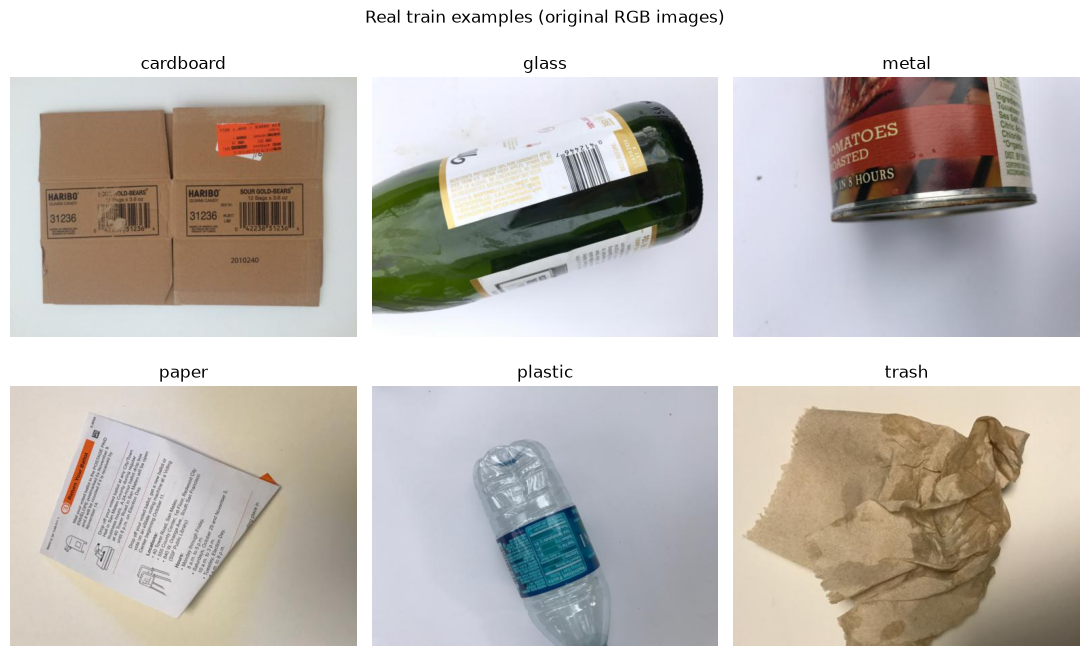

In [3]:
data = datasets.load_experiment_data(PROJECT_ROOT)
class_counts = datasets.dataset_table(data)
class_counts.loc["Total"] = class_counts.sum()
display(class_counts)
print("Class-to-index mapping:", {label: i for i, label in enumerate(data["classes"])})
print("Approved split SHA-256:", data["manifest_sha256"])
results.plot_examples(data, subset="train", seed=CONFIG["seed"])
plt.show()

## 4. Model and preprocessing

[ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
used Torchvision's `ResNet18_Weights.IMAGENET1K_V1` weights. Its feature extractor
and pooling were frozen, and its original classifier was replaced by a
six-output linear layer. The backbone remained in evaluation mode so
batch-normalization statistics stayed fixed.

Both subsets used bilinear resizing to a 256-pixel shorter edge, a 224 × 224
center crop, and ImageNet channel normalization. No augmentation was applied.

In [4]:
def build_model(pretrained=True):
    """This notebook's architecture; no model is built until the function is called."""
    from torch import nn
    from torchvision.models import resnet18, ResNet18_Weights

    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights if pretrained else None)
    model.requires_grad_(False)
    feature_count = model.fc.in_features
    model.fc = nn.Linear(feature_count, len(data["classes"]))
    return model, model.fc, weights.transforms(), weights

In [5]:
if MODE == "train":
    results.require_new_run(PROJECT_ROOT, MODEL_NAME, RUN_NAME)
    from src import experiment_training as training
    training.seed_everything(CONFIG["seed"])
    device = training.select_device(DEVICE_PREFERENCE)
    model, head, transform, weights = build_model(pretrained=True)
    run_config = training.make_config(
        data, MODEL_NAME, DISPLAY_NAME, RUN_NAME, model, head, weights, device,
        NOTEBOOK_NAME, CONFIG,
    )
elif MODE == "reload":
    run = results.load_run(PROJECT_ROOT, MODEL_NAME, RUN_NAME, data,
                           require_checkpoint=RESTORE_CHECKPOINT)
    run_config = run["config"]
    if RESTORE_CHECKPOINT:
        from src import experiment_training as training
        device = training.select_device(DEVICE_PREFERENCE)
        model, head, transform, weights = build_model(pretrained=False)
        model = training.restore_checkpoint(model, run, data, device)
        print("Checkpoint restored without training; recorded timings below are from the original run.")

if run_config is not None:
    display(pd.Series({key: run_config[key] for key in [
        "display_name", "weights", "device", "total_parameters", "trainable_parameters",
        "trainable_parameter_names", "preprocessing",
    ]}, name="Model information").to_frame())
    classifier_summary = run_config["architecture"].split("(fc): ", 1)[1].splitlines()[0]
    print("Replacement classifier:", classifier_summary)
else:
    print("Architecture definition is ready. Model construction waits for train or checkpoint-reload mode.")

,Model information
display_name,ResNet18
weights,ResNet18_Weights.IMAGENET1K_V1
device,mps
total_parameters,11179590
trainable_parameters,3078
trainable_parameter_names,"[fc.weight, fc.bias]"
preprocessing,"{'resize_size': [256], 'crop_size': [224], 'in..."


Replacement classifier: Linear(in_features=512, out_features=6, bias=True)


## 5. Training progress

All five epochs were completed on Apple MPS. The saved history records the
losses, validation performance, and duration of each epoch. Macro-F1 gave each
category equal weight when selecting the checkpoint.

In [6]:
if MODE == "train":
    run = training.train_baseline(data, model, head, transform, run_config, device)
elif MODE == "reload":
    print("Loaded saved results; no training or new timing measurements were performed.")
else:
    print("Review mode: training has not been executed.")

if run is not None:
    display(run["history"])

Loaded saved results; no training or new timing measurements were performed.


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,epoch_seconds
0,1,1.226513,0.542210,0.858409,0.693122,0.593491,9.308512
1,2,0.757393,0.740510,0.713102,0.767196,0.749114,6.348060
2,3,0.623675,0.788669,0.617888,0.788360,0.749736,6.274927
3,4,0.552679,0.818130,0.582785,0.806878,0.784084,6.319160
4,5,0.500281,0.834561,0.540672,0.833333,0.804440,6.291645


## 6. Learning curves

Training and validation loss decreased throughout the five epochs. Validation
macro-F1 also increased, and epoch 5 achieved the highest accuracy and macro-F1.
This final checkpoint was retained under the predefined selection rule.

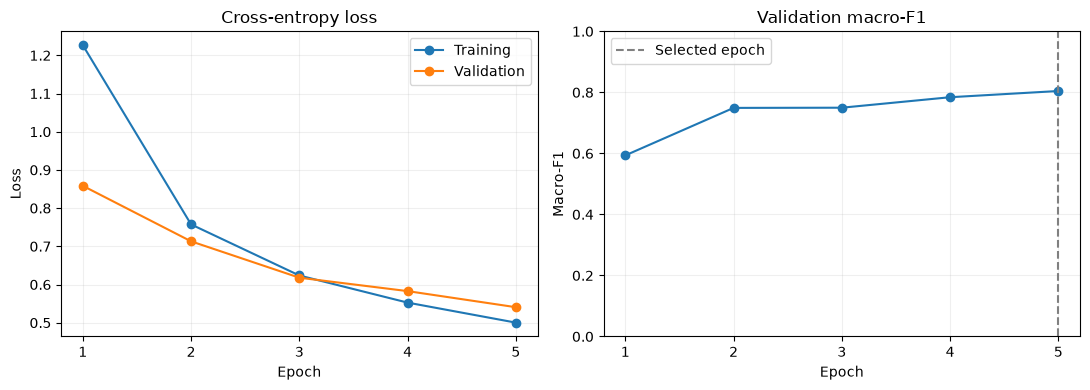

In [7]:
if run is not None:
    results.plot_history(run)
    plt.show()
else:
    print("Learning curves will appear after a real run is trained or reloaded.")

## 7. Validation metrics and confusion matrix

Cardboard had the highest F1 (0.9231), while paper had the highest recall
(0.9551). Trash remained the weakest category (F1 0.6111), with 11 of 20
validation images recognized. The gap between categories showed why overall
accuracy alone was insufficient to summarize this imbalanced dataset.

,Validation result
accuracy,0.833333
macro_f1,0.804440
weighted_f1,0.831568
validation_loss,0.540672
n_validation,378.000000
best_epoch,5.000000


,precision,recall,f1,support,one_vs_rest_accuracy
class,,,,,
cardboard,0.9643,0.8852,0.9231,61,0.9762
glass,0.7848,0.8267,0.8052,75,0.9206
metal,0.8519,0.7541,0.8000,61,0.9392
paper,0.8333,0.9551,0.8901,89,0.9444
plastic,0.8028,0.7917,0.7972,72,0.9233
trash,0.6875,0.5500,0.6111,20,0.9630


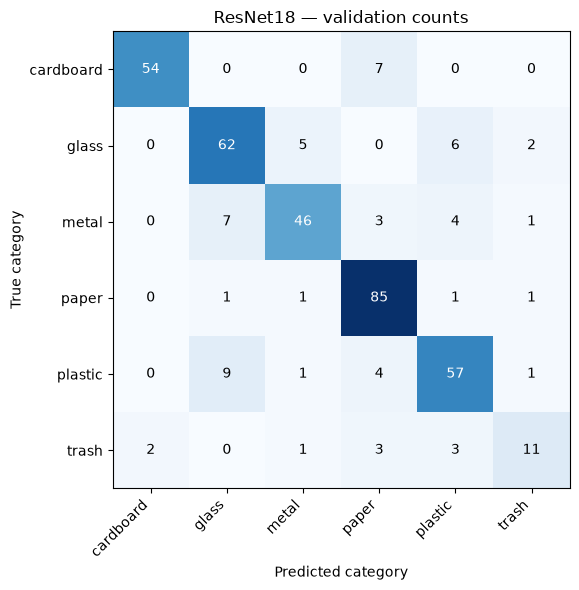

In [8]:
if run is not None:
    metrics = run["metrics"]
    display(pd.Series({key: metrics[key] for key in [
        "accuracy", "macro_f1", "weighted_f1", "validation_loss", "n_validation", "best_epoch"
    ]}, name="Validation result").to_frame())
    display(pd.DataFrame(metrics["per_class"]).set_index("class").round(4))
    results.plot_confusion(run)
    plt.show()
else:
    print("Validation metrics are pending an actual experiment.")

## 8. Correct predictions and error analysis

Plastic → glass was the most frequent confusion (nine images), followed by
cardboard → paper and metal → glass (seven each). The grids show six
low-confidence correct predictions and the eight most confident errors.

Two plastic bottles were classified as glass with confidence above 97%.
Printed cardboard and reflective packaging also appeared among the errors;
these examples showed that high confidence did not guarantee correct material
recognition.

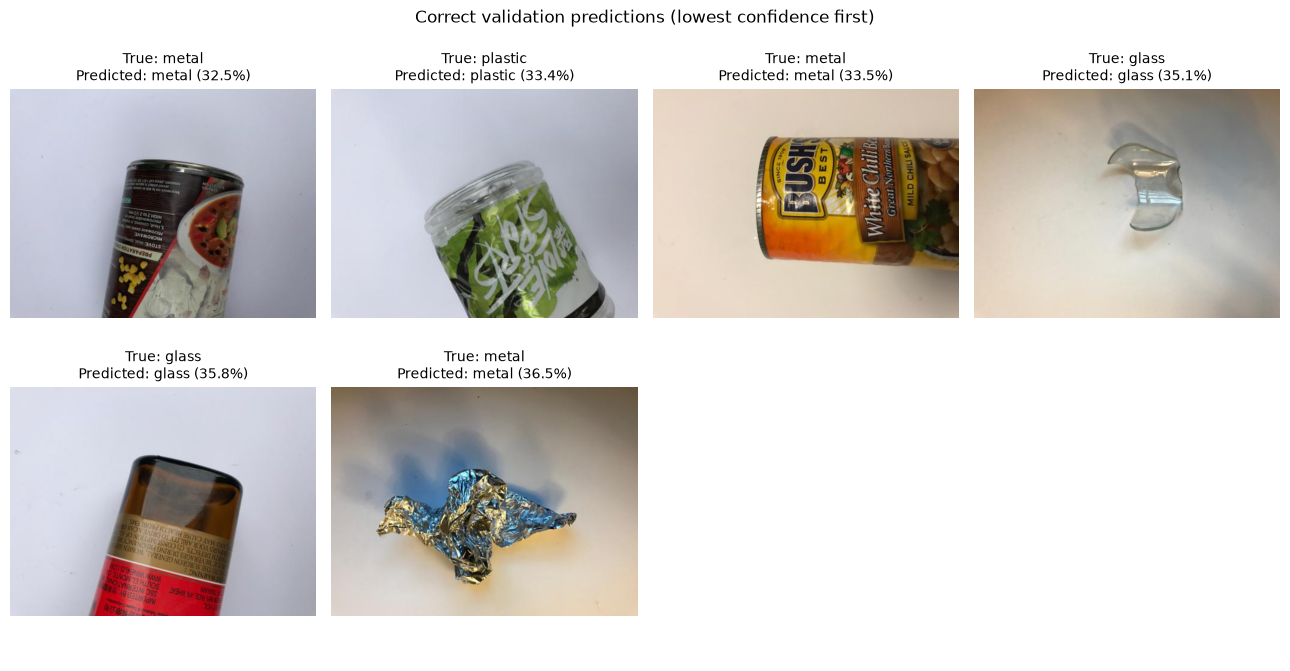

,path,true_label,predicted_label,confidence,correct
357,plastic/plastic95.jpg,plastic,glass,0.987851,False
356,plastic/plastic94.jpg,plastic,glass,0.973183,False
26,cardboard/cardboard266.jpg,cardboard,paper,0.966250,False
348,plastic/plastic467.jpg,plastic,metal,0.939360,False
148,metal/metal172.jpg,metal,plastic,0.879488,False
303,plastic/plastic180.jpg,plastic,glass,0.863713,False
358,trash/trash112.jpg,trash,metal,0.856866,False
45,cardboard/cardboard384.jpg,cardboard,paper,0.851609,False


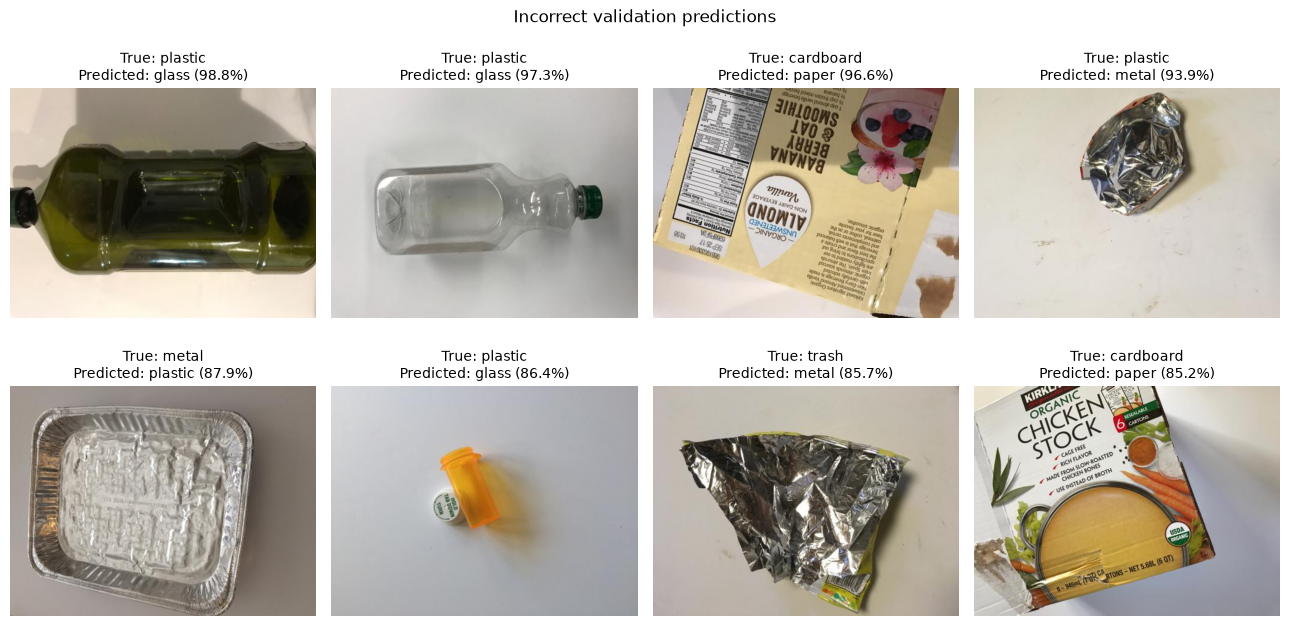

,true_label,predicted_label,Images
0,plastic,glass,9
1,cardboard,paper,7
2,metal,glass,7
3,glass,plastic,6
4,glass,metal,5


In [9]:
if run is not None:
    correct_examples = results.prediction_examples(run, correct=True, limit=6)
    results.plot_predictions(data, correct_examples, "Correct validation predictions (lowest confidence first)")
    plt.show()
    error_examples = results.prediction_examples(run, correct=False, limit=8)
    has_errors = (~run["predictions"]["correct"]).any()
    title = "Incorrect validation predictions" if has_errors else "No errors recorded: low-confidence correct predictions"
    display(error_examples[["path", "true_label", "predicted_label", "confidence", "correct"]])
    results.plot_predictions(data, error_examples, title)
    plt.show()
    display(results.confusion_pairs(run))
else:
    print("Prediction examples require real saved validation predictions.")

## 9. Training time and local inference latency

Timing used batch size one on Apple MPS, with 10 warm-up and 50 timed passes over
20 seeded validation images. Forward timing covered the model alone; end-to-end
timing included image decoding, preprocessing, transfer, and prediction.

Training took 34.54 seconds, and median end-to-end latency was 4.86 ms. These
measurements supported responsive local predictions under warm-run conditions;
model startup, camera capture, and the application interface were not measured.

In [10]:
if run is not None:
    timing = run["metrics"]["latency"]
    print(f"Total training time: {run['metrics']['training_seconds']:.2f} seconds")
    print("Measured device:", timing["device"])
    latency_table = pd.DataFrame({
        name: {key: timing[name][key] for key in ["mean_ms", "median_ms", "p95_ms"]}
        for name in ["forward", "end_to_end"]
    }).T.rename_axis("Timing scope")
    display(latency_table.round(3))
    print("Completed run:", run["directory"].relative_to(PROJECT_ROOT))
else:
    print("No training duration or inference latency has been measured yet.")

Total training time: 34.54 seconds
Measured device: mps


,mean_ms,median_ms,p95_ms
Timing scope,,,
forward,2.740,2.730,2.795
end_to_end,5.018,4.858,5.941


Completed run: results/experiments/resnet18/baseline_seed42_5epochs


## 10. Observations and interpretation

The selected checkpoint achieved 83.33% validation accuracy and macro-F1 0.8044.
The results reflected one seed and one split with unresolved object
relationships, limiting conclusions about performance on new objects or
camera images. The held-out test set was not evaluated.